In [1]:
import glob

In [2]:
from PIL import Image

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.utils import shuffle
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.model_selection import StratifiedKFold, GridSearchCV

In [4]:
#DATA

In [5]:
no_smile = glob.glob("data/non_smile/*.jpg")
smile = glob.glob("data/smile/*.jpg")
test = glob.glob("data/test/*.jpg")

In [6]:
type(no_smile)

list

In [7]:
len(no_smile), len(smile)

(603, 600)

In [8]:
#Converting to Lower Scale ("Gray_Scale")

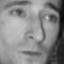

In [10]:
pic1 = Image.open(no_smile[22]).convert("L")
pic1

In [11]:
pic1.size

(64, 64)

In [12]:
pixel_array = np.array(pic1)

In [13]:
pixel_array

array([[132, 135, 138, ...,  52,  33,  21],
       [133, 136, 139, ...,  52,  33,  21],
       [134, 136, 140, ...,  51,  32,  20],
       ...,
       [119, 127, 134, ...,  36,  36,  37],
       [108, 117, 126, ...,  37,  36,  37],
       [ 98, 108, 117, ...,  35,  34,  35]], shape=(64, 64), dtype=uint8)

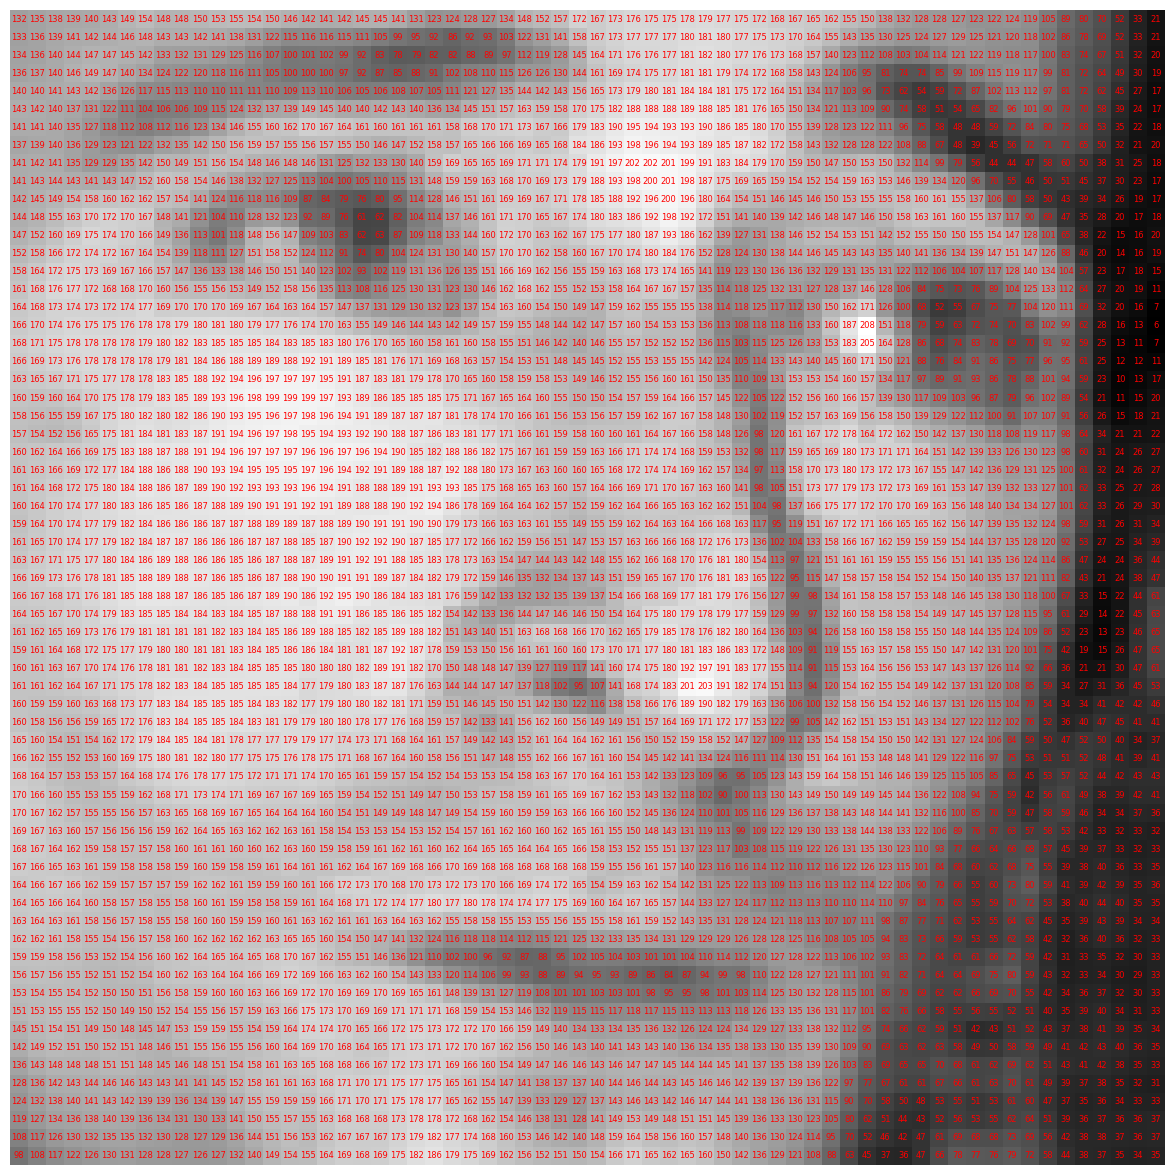

In [14]:
plt.figure(figsize=(15, 15))
plt.imshow(pixel_array, cmap="gray", interpolation="nearest")

# Showing pixel values which is overlaid on image
for i in range(64):
    for j in range(64):
        plt.text(j, i, pixel_array[i, j], ha="center", va="center", fontsize=6, color="red")

plt.axis("off")
plt.show()

In [15]:
data = []
labels = []

In [16]:
#Loading Smiling Images
for img_name in smile:
    img = Image.open(img_name).convert("L")
    img_array = np.array(img).flatten()  
    data.append(img_array)
    labels.append(1)  
#1 = Smiling

In [17]:
#Loading Non-Smiling Images
for img_name in no_smile:
    img = Image.open(img_name).convert("L")  
    img_array = np.array(img).flatten()  
    data.append(img_array)
    labels.append(0)  
#0 = Non-Smiling

In [18]:
len(data)

1203

In [19]:
type(data[0])

numpy.ndarray

In [20]:
type(labels[0])

int

In [23]:
data

[array([232, 233, 228, ..., 122, 136, 144], shape=(4096,), dtype=uint8),
 array([ 94, 100, 103, ..., 158, 153, 146], shape=(4096,), dtype=uint8),
 array([157, 155, 156, ..., 213, 211, 222], shape=(4096,), dtype=uint8),
 array([106, 111, 118, ..., 180, 180, 189], shape=(4096,), dtype=uint8),
 array([172, 172, 171, ...,  65,  63,  64], shape=(4096,), dtype=uint8),
 array([110, 112, 116, ..., 121, 121, 122], shape=(4096,), dtype=uint8),
 array([ 54,  79,  93, ..., 114, 109, 105], shape=(4096,), dtype=uint8),
 array([58, 75, 93, ..., 73, 76, 85], shape=(4096,), dtype=uint8),
 array([ 91, 104, 122, ...,  67,  69,  74], shape=(4096,), dtype=uint8),
 array([107, 109, 102, ..., 104, 105, 107], shape=(4096,), dtype=uint8),
 array([124, 139, 127, ..., 177, 181, 182], shape=(4096,), dtype=uint8),
 array([134, 123, 103, ..., 105,  99, 100], shape=(4096,), dtype=uint8),
 array([27, 31, 33, ..., 81, 54, 26], shape=(4096,), dtype=uint8),
 array([135, 144, 128, ..., 241, 236, 251], shape=(4096,), dtyp

In [25]:
X = np.array(data)
y = np.array(labels)

In [27]:
X,y

(array([[232, 233, 228, ..., 122, 136, 144],
        [ 94, 100, 103, ..., 158, 153, 146],
        [157, 155, 156, ..., 213, 211, 222],
        ...,
        [ 27,  39,  58, ...,  10,   7,   9],
        [ 51,  23,   4, ..., 107, 102,  98],
        [ 83,  75,  70, ...,  90,  85, 125]],
       shape=(1203, 4096), dtype=uint8),
 array([1, 1, 1, ..., 0, 0, 0], shape=(1203,)))

In [28]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, shuffle=True)

In [29]:
X_train.shape, X_test.shape

((962, 4096), (241, 4096))

In [30]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

In [31]:
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [32]:
model = LogisticRegression()
model.fit(X_train_scaled, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul

In [33]:
y_pred = model.predict(X_test_scaled)

In [34]:
y_pred_train = model.predict(X_train_scaled)

In [35]:
y_pred

array([0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 1, 1, 0, 1, 0, 1, 0, 0,
       1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1,
       0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 1, 0,
       1, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 1, 0, 0, 0, 1, 1, 0, 1, 1, 1, 1,
       0, 1, 0, 1, 1, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0,
       1, 1, 1, 0, 1, 0, 0, 0, 1, 1, 0, 1, 1, 1, 1, 0, 0, 0, 0, 1, 0, 1,
       1, 1, 0, 1, 1, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 1, 1, 1, 0, 1, 1, 0,
       1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 0, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0,
       1, 1, 0, 0, 0, 1, 0, 1, 0, 0, 1, 1, 0, 0, 1, 1, 1, 0, 0, 1, 1, 1,
       0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 1, 1, 0, 0, 0, 1, 0,
       0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 1, 1, 0, 1, 0, 1, 1, 0, 1, 0, 0])

In [37]:
accuracy = accuracy_score(y_test, y_pred)

In [38]:
accuracy

0.8506224066390041

In [39]:
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

Confusion Matrix:
 [[ 97  19]
 [ 17 108]]


In [40]:
print("Classification Report:\n", classification_report(y_test, y_pred))

Classification Report:
               precision    recall  f1-score   support

           0       0.85      0.84      0.84       116
           1       0.85      0.86      0.86       125

    accuracy                           0.85       241
   macro avg       0.85      0.85      0.85       241
weighted avg       0.85      0.85      0.85       241



In [51]:
image = Image.open("D:\ML_Fold\Emotion_predict_project\smile4images.jpg").convert("L")  
resized_image = image.resize((64, 64))

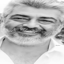

In [52]:
resized_image

In [53]:
img_array = np.array(resized_image).flatten()
sc = scaler.transform(img_array.reshape(1,-1))

In [54]:
model.predict(sc)

array([1])

In [63]:
image = Image.open("D:\ML_Fold\Emotion_predict_project\sad3img.jpg").convert("L")  
resized_image = image.resize((64, 64))

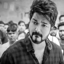

In [64]:
resized_image

In [65]:
img_array = np.array(resized_image).flatten()
sc = scaler.transform(img_array.reshape(1,-1))

In [66]:
model.predict(sc)

array([0])